In [10]:
from dotenv import dotenv_values
from openai import OpenAI
from IPython.display import Markdown, Image
import requests
import base64

In [11]:
env = dotenv_values("../../.env")
openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

In [12]:
response = openai_client.images.generate(
    model="gpt-image-1",
    prompt="odręczny rysunek pociągu",
    size="1024x1024",
    quality="low",
    n=1
)

In [13]:
Markdown(response.data[0].revised_prompt)

<IPython.core.display.Markdown object>

In [14]:
image_base64 = response.data[0].b64_json
image_bytes = base64.b64decode(image_base64)

with open("rysunek_pociagu.png", "wb") as f:
    f.write(image_bytes)

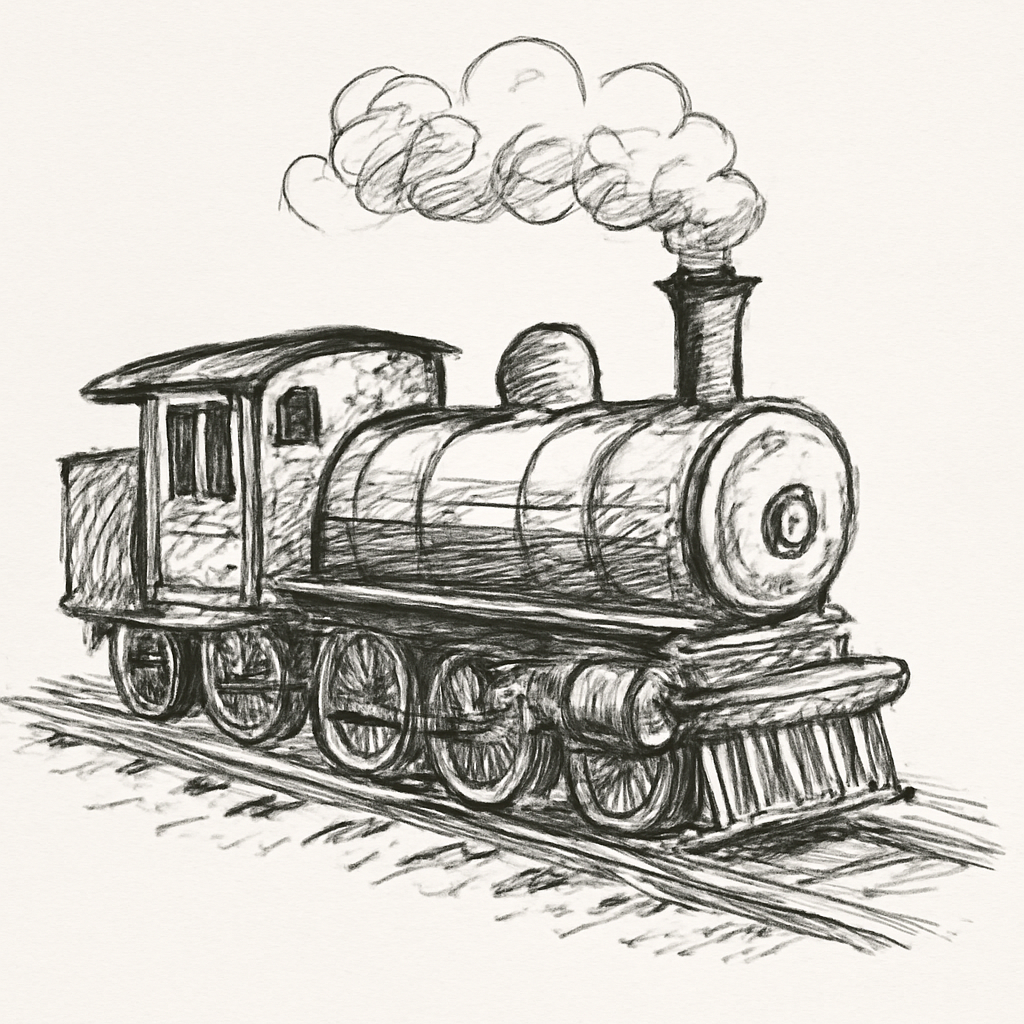

In [15]:
Image("rysunek_pociagu.png")

In [20]:
def generate_image(
        text,
        output_path
):
    response = openai_client.images.generate(
        model="gpt-image-1",
        prompt=text,
        size="1024x1024",
        quality="low",
        n=1
    )
    image_base64 = response.data[0].b64_json
    image_bytes = base64.b64decode(image_base64)
    with open(output_path, "wb") as f:
        f.write(image_bytes)

    return Image(output_path)


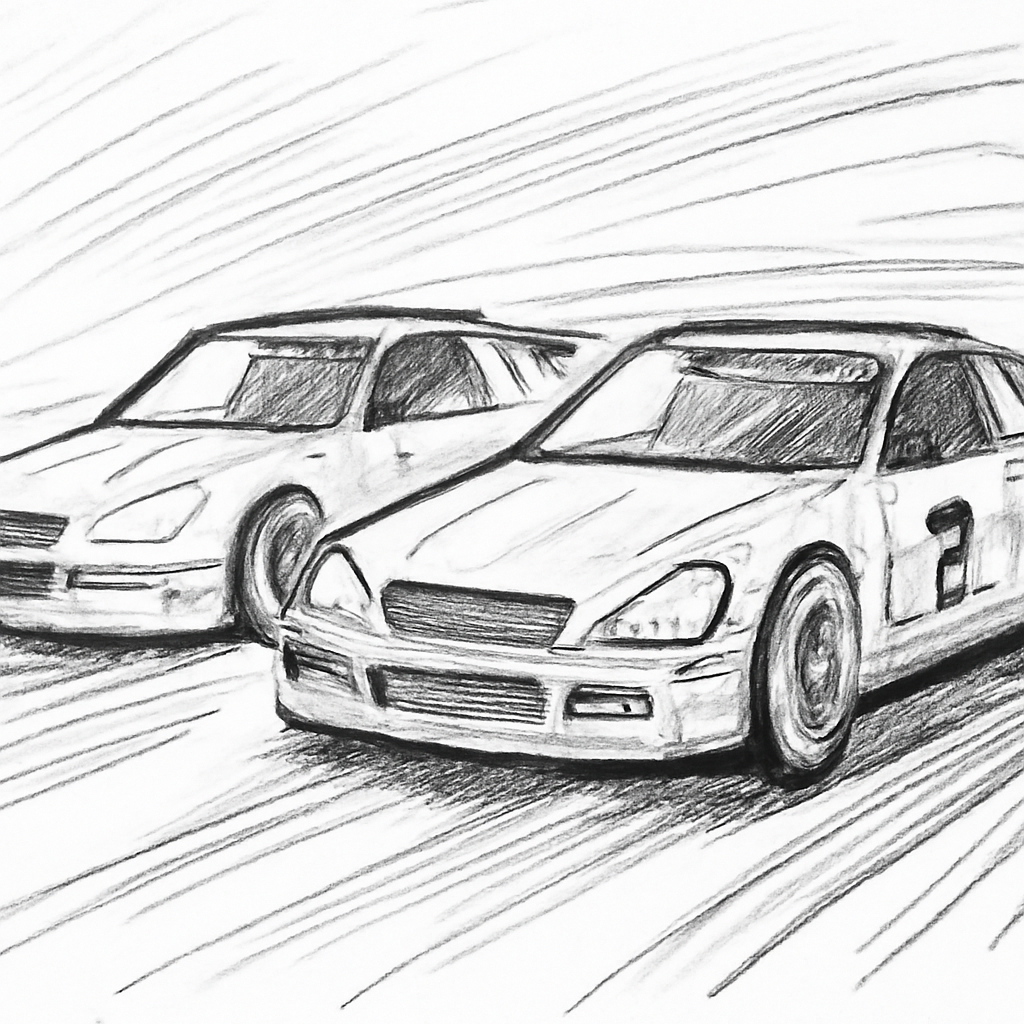

In [21]:
generate_image(
    text="rysunek odręczny ścigających się samochodów",
    output_path="wygenerowany_obrazek.png"
)
Image("wygenerowany_obrazek.png")